# Task 1 (A & B) — Exploratory Data Analysis & Preprocessing
### Metro Interstate Traffic Volume (I-94, Minneapolis–St Paul)

**Problem definition.** Forecast the **hourly westbound traffic volume** on Interstate 94 at MnDOT ATR station 301 (between Minneapolis and St Paul, Minnesota). The target is `traffic_volume` (vehicles per hour). This is a **one-step-ahead regression forecast**: given the traffic history up to hour *t-1*, the calendar, and the weather, predict the volume for hour *t*.

**Why this dataset.**
* **Clear timestamp** — `date_time`, hourly, Oct 2012 – Sep 2018.
* **Meaningful target** — hourly volume drives ramp metering, incident response, roadwork scheduling and congestion alerts. Accurate short-term forecasts are a core input for Intelligent Transport Systems.
* **Several variables over time** — temperature, rain, snow, cloud cover, a weather category and holidays. These are external drivers we can test against the target.
* **Real-world messiness** — duplicate timestamps, missing hours (including a 10-month outage) and impossible sensor readings. This gives the preprocessing stage real problems to solve.

Source: Kaggle *“Metro Interstate Traffic Volume”* (mirrored from the UCI Machine Learning Repository, dataset #492, John Hogue, 2019).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))          # make `src` importable from notebooks/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from src import preprocessing as pp
from src.config import RAW_DATA_PATH, PROCESSED_DATA_PATH
from src.plotting import apply_style, save, SERIES, SEQUENTIAL, DIVERGING, NEUTRAL, TEXT_SECONDARY

apply_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

## A. Understanding the dataset
### A1. First look

In [2]:
raw = pp.load_raw(RAW_DATA_PATH)
print("Shape:", raw.shape)
display(raw.head())
raw.info()

Shape: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              61 non-null     object        
 1   temp                 48204 non-null  float64       
 2   rain_1h              48204 non-null  float64       
 3   snow_1h              48204 non-null  float64       
 4   clouds_all           48204 non-null  int64         
 5   weather_main         48204 non-null  object        
 6   weather_description  48204 non-null  object        
 7   date_time            48204 non-null  datetime64[ns]
 8   traffic_volume       48204 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(2), object(3)
memory usage: 3.3+ MB


| Column | Meaning |
|---|---|
| `holiday` | US national / regional holiday name (only on the 00:00 row of that day) |
| `temp` | Average temperature in **Kelvin** |
| `rain_1h` / `snow_1h` | Precipitation (mm) in the hour |
| `clouds_all` | Cloud cover (%) |
| `weather_main` / `weather_description` | Short and long weather category |
| `date_time` | Local hour of the observation |
| `traffic_volume` | **Target** — westbound vehicles in that hour |

### A2. Time range and frequency / granularity

In [3]:
print("First timestamp:", raw.date_time.min())
print("Last timestamp: ", raw.date_time.max())
span = raw.date_time.max() - raw.date_time.min()
print(f"Span: {span.days} days (~{span.days/365.25:.1f} years)")

steps = raw.date_time.drop_duplicates().sort_values().diff().value_counts().head(8)
print("\nMost common gaps between consecutive unique timestamps:")
print(steps)

First timestamp: 2012-10-02 09:00:00
Last timestamp:  2018-09-30 23:00:00
Span: 2189 days (~6.0 years)

Most common gaps between consecutive unique timestamps:
date_time
0 days 01:00:00    37986
0 days 02:00:00     2192
0 days 03:00:00      201
0 days 04:00:00       59
0 days 05:00:00       33
0 days 06:00:00       17
0 days 08:00:00       13
0 days 10:00:00       13
Name: count, dtype: int64


**Interpretation.** The data runs from **2 Oct 2012 09:00 to 30 Sep 2018 23:00**, about six years. The natural granularity is **hourly**: almost every step between consecutive unique timestamps is exactly 1 hour. The other step sizes are missing hours, covered in A4.

### A3. Duplicate timestamps

In [4]:
dups = raw.date_time.duplicated().sum()
print(f"Rows: {len(raw):,} | unique hours: {raw.date_time.nunique():,} | duplicate rows: {dups:,}")
print("Max rows for one hour:", raw.groupby('date_time').size().max())

varying = raw.groupby("date_time")[["temp","rain_1h","snow_1h","clouds_all","traffic_volume","weather_main"]].nunique().max()
print("\nMax distinct values within one hour, per column:")
print(varying)
display(raw[raw.date_time.duplicated(keep=False)].head(6))

Rows: 48,204 | unique hours: 40,575 | duplicate rows: 7,629
Max rows for one hour: 6

Max distinct values within one hour, per column:
temp              2
rain_1h           2
snow_1h           1
clouds_all        2
traffic_volume    1
weather_main      5
dtype: int64


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
178,NaN,281.25,0.0,0.0,99,Rain,light rain,2012-10-10 07:00:00,6793
179,NaN,281.25,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 07:00:00,6793
180,NaN,280.10,0.0,0.0,99,Rain,light rain,2012-10-10 08:00:00,6283
181,NaN,280.10,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 08:00:00,6283
182,NaN,279.61,0.0,0.0,99,Rain,light rain,2012-10-10 09:00:00,5680
183,NaN,279.61,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 09:00:00,5680


**Interpretation.** 7,629 rows share a timestamp with another row. Inside each duplicate group, `traffic_volume` is **always identical**. Only the weather *condition* differs (e.g. *light rain* and *light intensity drizzle* in the same hour). So these are not double-counted traffic. The source simply adds a row for each extra weather condition.

**Handling:** collapse to **one row per hour**. Numeric values are averaged (they are identical or near-identical), and the **most severe** condition is kept as `weather_main` (Thunderstorm > Squall > Snow > Rain > … > Clear). The number of conditions is kept as `n_conditions`. In the SQL/MongoDB designs (Task 2) the full list of conditions is kept, as a junction table and an embedded array.

### A4. Missing values

In [5]:
print("Explicit nulls per column (raw):")
print(raw.isna().sum())

unique = raw.drop_duplicates("date_time").set_index("date_time")
full_index = pd.date_range(unique.index.min(), unique.index.max(), freq="h")
missing_hours = full_index.difference(unique.index)
print(f"\nExpected hourly slots: {len(full_index):,}")
print(f"Observed hours:        {len(unique):,}")
print(f"Missing hours:         {len(missing_hours):,} ({len(missing_hours)/len(full_index):.1%})")

# Lengths of each consecutive run of missing hours
s = pd.Series(1, index=missing_hours)
run_id = (s.index.to_series().diff() != pd.Timedelta("1h")).cumsum()
runs = pd.DataFrame({"start": s.groupby(run_id).apply(lambda x: x.index.min()),
                     "hours": s.groupby(run_id).size()})
print(f"\nNumber of gaps: {len(runs):,}")
print(pd.cut(runs.hours, [0,1,3,6,24,168,10_000],
             labels=["1 h","2-3 h","4-6 h","7-24 h","1-7 days",">1 week"]).value_counts().sort_index())
print("\nLongest gaps:")
display(runs.sort_values("hours", ascending=False).head(5))

Explicit nulls per column (raw):
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64



Expected hourly slots: 52,551
Observed hours:        40,575
Missing hours:         11,976 (22.8%)



Number of gaps: 2,588
hours
1 h         2192
2-3 h        260
4-6 h         60
7-24 h        65
1-7 days       9
>1 week        2
Name: count, dtype: int64

Longest gaps:


,start,hours
896,2014-08-08 02:00:00,7386
664,2013-10-27 02:00:00,242
902,2015-06-14 21:00:00,117
783,2014-04-29 09:00:00,116
1024,2015-10-23 12:00:00,92


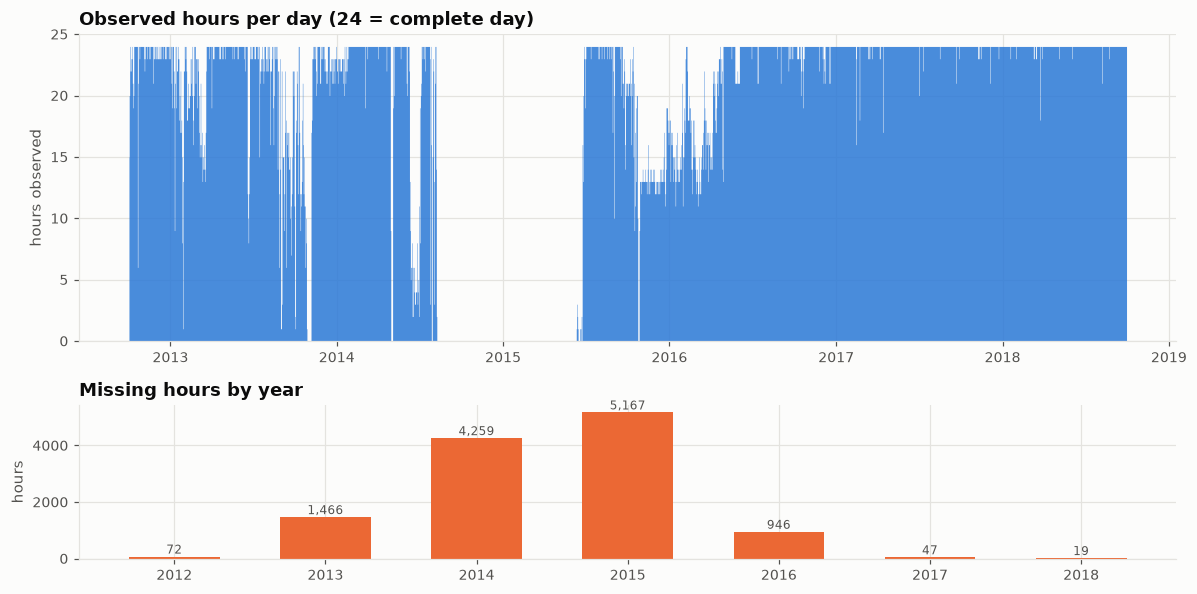

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), gridspec_kw={"height_ratios": [2, 1]})
daily_obs = unique.traffic_volume.resample("D").count()
axes[0].fill_between(daily_obs.index, daily_obs.values, step="mid", color=SERIES[0], alpha=0.85, linewidth=0)
axes[0].set_title("Observed hours per day (24 = complete day)")
axes[0].set_ylabel("hours observed")
axes[0].set_ylim(0, 25)
miss_year = pd.Series(missing_hours.year).value_counts().sort_index()
axes[1].bar(miss_year.index.astype(str), miss_year.values, color=SERIES[1], width=0.6)
for x, v in zip(miss_year.index.astype(str), miss_year.values):
    axes[1].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8, color=TEXT_SECONDARY)
axes[1].set_title("Missing hours by year")
axes[1].set_ylabel("hours")
fig.tight_layout(); save(fig, "a4_missing_data"); plt.show()

**Findings.**
* **Explicit nulls:** only `holiday`, which is null on every non-holiday row. It is a *“no holiday”* flag, not missing data. The holiday name is also only written on the **00:00** row of each holiday. The other 23 hours of that day are unlabelled.
* **Implicit missing hours:** 11,976 of 52,551 expected hourly slots (22.8%) have no row. Most gaps are **1 hour** long. A few are long, and one outage runs **from 8 Aug 2014 to 11 Jun 2015 (7,386 hours ≈ 10 months)**. 2014–2015 are the most affected years.

**How we handle them and why.**
| Problem | Method | Why |
|---|---|---|
| `holiday` null | Map to “no holiday”, spread the name to all 24 hours of the date, create `is_holiday` 0/1 | A holiday is a property of the *day*. Leaving 23 hours unlabelled would hide the effect. |
| Gaps ≤ 3 h (2,452 of the 2,588 gaps; 2,192 are a single hour) | **Time-based linear interpolation** for numeric columns, forward-fill for the weather category, rows flagged `is_imputed = 1` | Traffic and weather change smoothly over 1–3 hours. Interpolation keeps the series regular, so `shift()`-based lags stay correct. The flag keeps the imputation auditable. |
| Gaps > 3 h (incl. the 10-month outage) | **Left as NaN — no imputation.** Rows whose lag/rolling window touches a long gap are dropped before modelling | Inventing hours, days or months of traffic would create fake daily and weekly cycles and leak made-up values into lag features. Dropping a few windows is safer than fabricating data. |
| Mean/median filling | **Rejected** | Traffic swings from about 300 to 6,000 vehicles within hours. A global mean would destroy the daily cycle. |

### A5. Invalid values / outliers

Temperatures at 0 K (impossible): 10
Coldest valid temp (C): -29.8
Rain > 100 mm in one hour: 1 | value: 9831.3
Second-highest rain_1h: 55.63
Hours with zero traffic: 2


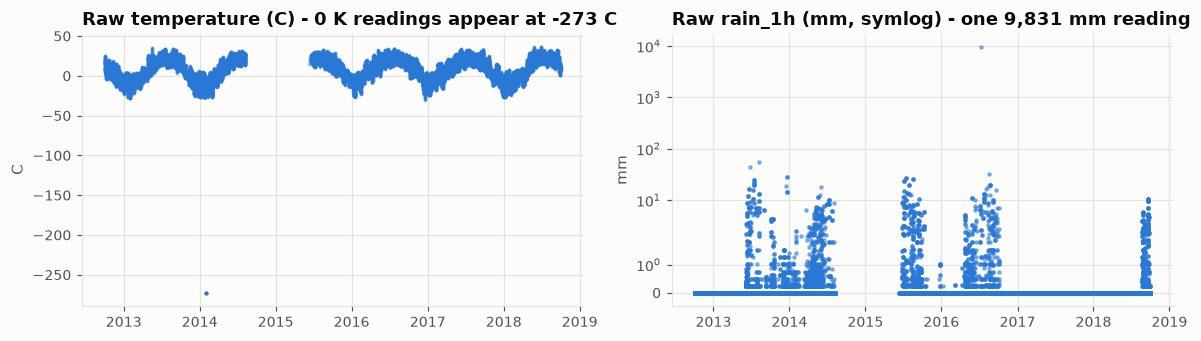

In [7]:
print("Temperatures at 0 K (impossible):", (raw.temp == 0).sum())
print("Coldest valid temp (C):", round(raw.loc[raw.temp > 0, "temp"].min() - 273.15, 1))
print("Rain > 100 mm in one hour:", (raw.rain_1h > 100).sum(), "| value:", raw.rain_1h.max())
print("Second-highest rain_1h:", raw.rain_1h.sort_values().iloc[-2])
print("Hours with zero traffic:", (raw.traffic_volume == 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].scatter(raw.date_time, raw.temp - 273.15, s=2, color=SERIES[0], alpha=0.4)
axes[0].set_title("Raw temperature (C) - 0 K readings appear at -273 C"); axes[0].set_ylabel("C")
axes[1].scatter(raw.date_time, raw.rain_1h, s=4, color=SERIES[0], alpha=0.5)
axes[1].set_yscale("symlog"); axes[1].set_title("Raw rain_1h (mm, symlog) - one 9,831 mm reading"); axes[1].set_ylabel("mm")
fig.tight_layout(); save(fig, "a5_invalid_values"); plt.show()

**Interpretation.** Ten rows report **0 K (−273 °C)**, a sensor failure. The coldest plausible value is −29.8 °C. One hour reports **9,831 mm of rain**, about 30× the world record for an hour; the next-largest value is 55.6 mm. Both are set to **NaN** and then handled with the missing-value rules above. The temperature failures come in runs of 4–6 hours, so those rows are excluded rather than interpolated. The **zero-traffic hours** are kept. They are rare, physically possible (e.g. full road closures for construction or incidents) and cannot be distinguished from real events, so they are not altered.

### A6. Apply the preprocessing pipeline

In [8]:
hourly = pp.clean_raw(raw)                 # 1 row per observed hour, invalid values -> NaN
grid = pp.to_hourly_grid(hourly)           # regular hourly index, short gaps filled
features = pp.build_features(grid)         # calendar + weather + lag + moving-average features

print(f"Raw rows:                     {len(raw):,}")
print(f"After de-duplication:         {len(hourly):,}")
print(f"Regular hourly grid:          {len(grid):,}")
print(f"  - hours imputed (gap<=3h):  {grid.is_imputed.sum():,}")
print(f"  - hours still missing:      {grid.traffic_volume.isna().sum():,}")
print(f"Model-ready rows (no NaN):    {len(features):,}  ({len(pp.FEATURE_COLUMNS)} features)")

PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
features.to_csv(PROCESSED_DATA_PATH)
print("Saved ->", PROCESSED_DATA_PATH.relative_to(PROCESSED_DATA_PATH.parents[2]))
display(features[["traffic_volume","temp_c","weather_main","is_holiday","lag_1","lag_24","lag_168","roll_mean_24","roll_mean_168"]].tail())

Raw rows:                     48,204
After de-duplication:         40,575
Regular hourly grid:          52,551
  - hours imputed (gap<=3h):  2,771
  - hours still missing:      9,205
Model-ready rows (no NaN):    36,568  (33 features)


Saved -> data\processed\traffic_hourly_clean.csv.gz


,traffic_volume,temp_c,weather_main,is_holiday,lag_1,lag_24,lag_168,roll_mean_24,roll_mean_168
date_time,,,,,,,,,
2018-09-30 19:00:00,3543.0,10.30,Clouds,0,3947.0,3818.0,3516.0,2741.041667,3390.250000
2018-09-30 20:00:00,2781.0,9.61,Clouds,0,3543.0,3338.0,2846.0,2729.583333,3390.410714
2018-09-30 21:00:00,2159.0,9.58,Thunderstorm,0,2781.0,2950.0,2346.0,2706.375000,3390.023810
2018-09-30 22:00:00,1450.0,8.94,Clouds,0,2159.0,2607.0,1635.0,2673.416667,3388.910714
2018-09-30 23:00:00,954.0,8.97,Clouds,0,1450.0,3856.0,934.0,2625.208333,3387.809524


### A7. Statistical distribution of numerical columns

In [9]:
num = hourly[["temp","rain_1h","snow_1h","clouds_all","traffic_volume"]].copy()
num["temp"] = num["temp"] - 273.15
num = num.rename(columns={"temp": "temp_c"})
summary = num.describe().T
summary["skew"] = num.skew()
summary["kurtosis"] = num.kurt()
summary["% zero"] = (num == 0).mean() * 100
display(summary.round(2))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,% zero
temp_c,40565.0,8.24,13.09,-29.76,-1.31,9.72,19.13,36.92,-0.38,-0.69,0.09
rain_1h,40574.0,0.08,0.77,0.00,0.00,0.00,0.00,55.63,28.64,1321.82,94.94
snow_1h,40575.0,0.00,0.01,0.00,0.00,0.00,0.00,0.51,65.91,4968.37,99.92
clouds_all,40575.0,44.20,38.68,0.00,1.00,40.00,90.00,100.00,0.03,-1.76,4.84
traffic_volume,40575.0,3290.65,1984.77,0.00,1248.50,3427.00,4952.00,7280.00,-0.11,-1.30,0.00


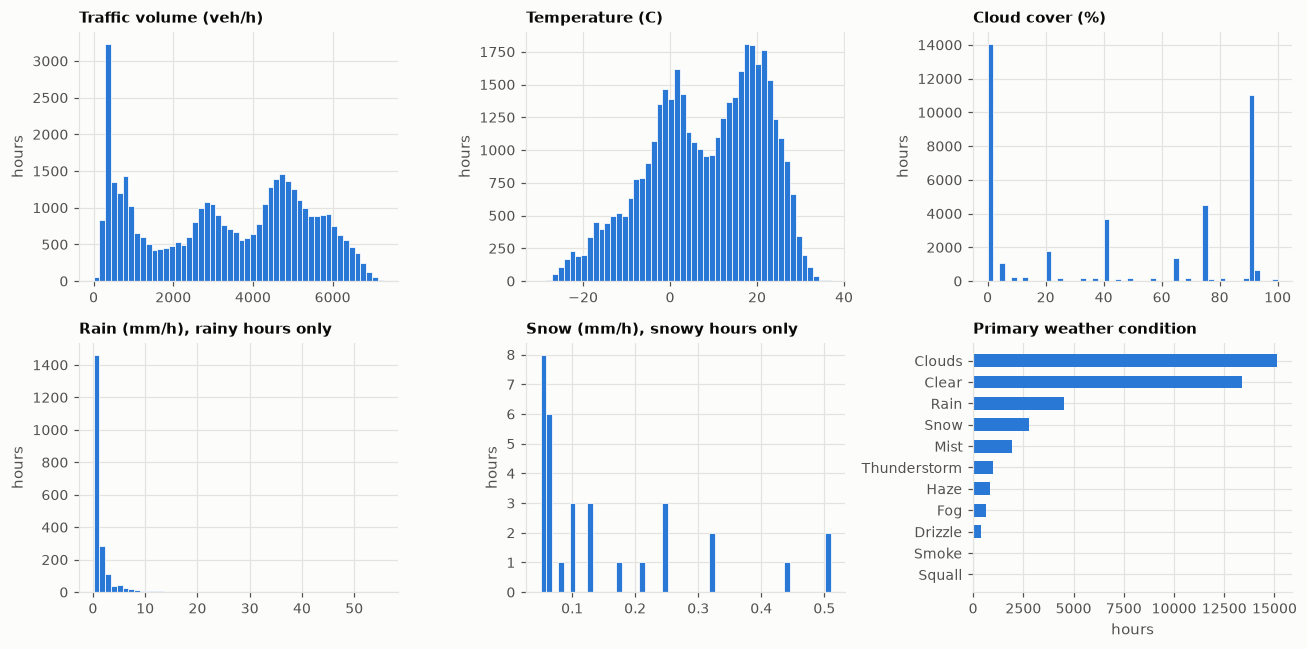

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
specs = [("traffic_volume", "Traffic volume (veh/h)", False),
         ("temp_c", "Temperature (C)", False),
         ("clouds_all", "Cloud cover (%)", False),
         ("rain_1h", "Rain (mm/h), rainy hours only", True),
         ("snow_1h", "Snow (mm/h), snowy hours only", True)]
for ax, (col, title, positive_only) in zip(axes.flat, specs):
    data = num[col].dropna()
    if positive_only:
        data = data[data > 0]
    ax.hist(data, bins=50, color=SERIES[0], edgecolor="white", linewidth=0.5)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("hours")
wc = hourly.weather_main.value_counts()
axes.flat[5].barh(wc.index[::-1], wc.values[::-1], color=SERIES[0], height=0.6)
axes.flat[5].set_title("Primary weather condition", fontsize=10); axes.flat[5].set_xlabel("hours")
fig.tight_layout(); save(fig, "a7_distributions"); plt.show()

**Interpretation.**
* **`traffic_volume`** is **bimodal**, not normal (skew ≈ −0.1). One peak sits near **300–1,000 vehicles/h** (night hours) and a broad plateau near **4,500–6,000** (daytime). Mean 3,291, median 3,427, range 0–7,280. Hour of day explains most of the spread, so calendar features matter.
* **`temp_c`** is roughly symmetric and wide (−29.8 °C to 36.9 °C, mean 8.2 °C), matching Minnesota's seasons.
* **`rain_1h`** and **`snow_1h`** are **zero-inflated and heavily right-skewed** (skew 28.6 and 65.9). Only 5.1% of hours have rain and 0.08% have measured snow. Snow is better captured by the `weather_main = Snow` category (7% of hours) than by the near-empty `snow_1h` column.
* **`clouds_all`** is U-shaped: mostly clear (≈0–1%) or overcast (90%+).
* **Weather categories** are dominated by Clouds and Clear. Smoke and Squall are very rare (fewer than 15 hours each).

Tree-based models do not need these skewed inputs to be normally distributed, so no transformation was applied. The rare categories are kept as one-hot columns so inference always sees a fixed feature set.

---
## B. Analytical questions
Six questions. **Q1, Q3 and Q6 use moving averages and/or lagged features**, as required.

### Q1. Does traffic have a long-term increasing or decreasing trend? *(moving averages)*

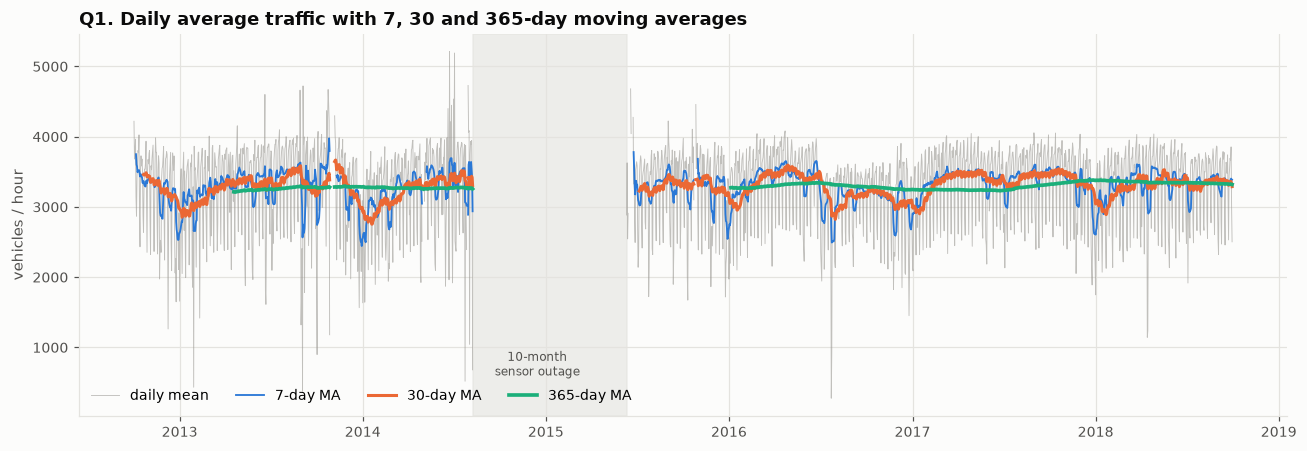

Linear trend: +14.6 veh/h per year  (p = 0.055, R^2 = 0.0020)
Relative to the mean: +0.44% per year


date_time,2012,2013,2014,2015,2016,2017,2018
mean veh/h,3227.0,3310.0,3270.0,3258.0,3194.0,3377.0,3324.0
observed hours,2103.0,7294.0,4501.0,3593.0,7838.0,8713.0,6533.0


In [11]:
daily = grid.traffic_volume.resample("D").mean()
ma7 = daily.rolling(7, min_periods=5).mean()
ma30 = daily.rolling(30, min_periods=20).mean()
ma365 = daily.rolling(365, min_periods=200).mean()
# hide MA values on days with no data so no line is drawn across the outage
ma7, ma30, ma365 = (m.where(daily.notna()) for m in (ma7, ma30, ma365))

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(daily.index, daily, color=NEUTRAL, linewidth=0.6, alpha=0.6, label="daily mean")
ax.plot(ma7.index, ma7, color=SERIES[0], linewidth=1.2, label="7-day MA")
ax.plot(ma30.index, ma30, color=SERIES[1], linewidth=2, label="30-day MA")
ax.plot(ma365.index, ma365, color=SERIES[2], linewidth=2.4, label="365-day MA")
ax.axvspan(pd.Timestamp("2014-08-08"), pd.Timestamp("2015-06-12"), color='#e4e3df', alpha=0.6)
ax.text(pd.Timestamp("2014-12-15"), 600, "10-month\nsensor outage", ha="center", fontsize=8, color=TEXT_SECONDARY)
ax.set_title("Q1. Daily average traffic with 7, 30 and 365-day moving averages")
ax.set_ylabel("vehicles / hour"); ax.legend(ncol=4, loc="lower left")
fig.tight_layout(); save(fig, "q1_trend_moving_averages"); plt.show()

d = daily.dropna()
t_years = (d.index - d.index[0]).days / 365.25
lr = stats.linregress(t_years, d.values)
print(f"Linear trend: {lr.slope:+.1f} veh/h per year  (p = {lr.pvalue:.3f}, R^2 = {lr.rvalue**2:.4f})")
print(f"Relative to the mean: {lr.slope / d.mean():+.2%} per year")
yearly = hourly.traffic_volume.groupby(hourly.index.year).agg(["mean", "size"]).round(0)
yearly.columns = ["mean veh/h", "observed hours"]
display(yearly.T)

**Interpretation.** The 7-day MA removes day-to-day noise but still shows weekly and holiday dips. The 30-day MA shows a **seasonal wave**: dips each winter (December–January, ≈3,050 veh/h) and recovery in spring. The 365-day MA removes seasonality and is **almost flat**, at about 3,200–3,380 veh/h every year.

A linear fit on daily means gives **+14.6 veh/h per year (≈ +0.4% per year, p ≈ 0.055)**. That is a very weak upward drift, not significant at the 5% level. 2017–2018 are the highest years (3,377 and 3,324). **Conclusion: no meaningful long-term trend. The series is level-stationary, with strong seasonality.** For modelling, this means a model trained on 2015–2017 should carry over to 2018 without de-trending. The year 2014–2015 averages are less reliable because of the outage, so the moving averages were computed with `min_periods` so they do not bridge the gap.

### Q2. What daily and weekly seasonal patterns exist?

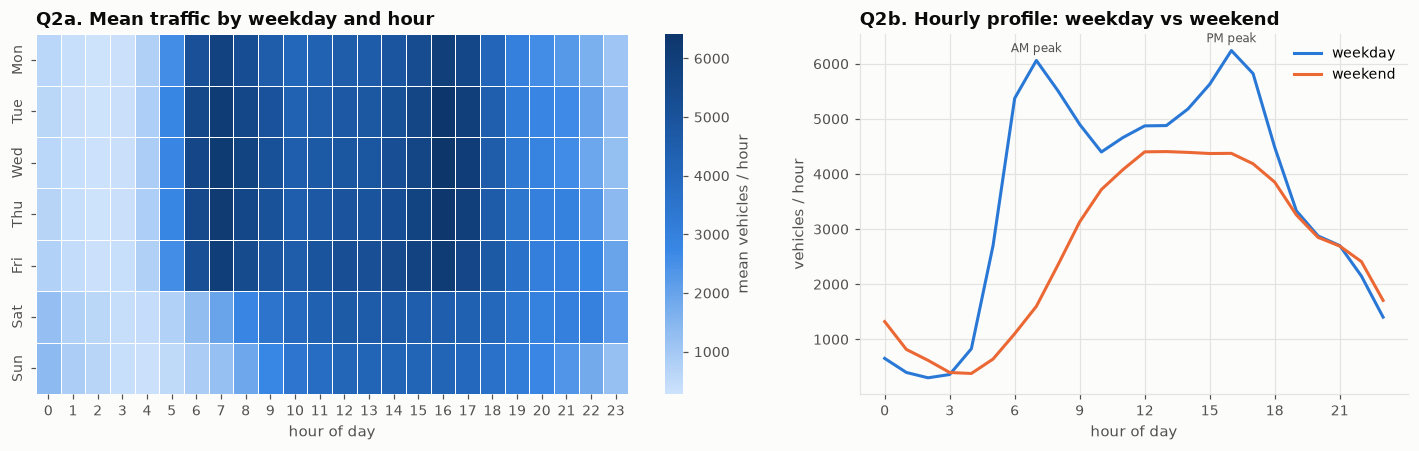

Weekday mean: 3557 | weekend mean: 2624 | weekend is -26.2%
Weekday peak hours: {16: 6241.0, 7: 6061.0, 17: 5823.0}
Monthly mean: {1: 3060.0, 2: 3231.0, 3: 3382.0, 4: 3374.0, 5: 3378.0, 6: 3422.0, 7: 3238.0, 8: 3430.0, 9: 3319.0, 10: 3388.0, 11: 3216.0, 12: 3040.0}


In [12]:
prof = hourly.groupby([hourly.index.dayofweek, hourly.index.hour]).traffic_volume.mean().unstack()
prof.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.35, 1]})
sns.heatmap(prof, ax=axes[0], cmap=SEQUENTIAL, cbar_kws={"label": "mean vehicles / hour"}, linewidths=0.4, linecolor="white")
axes[0].set_title("Q2a. Mean traffic by weekday and hour"); axes[0].set_xlabel("hour of day"); axes[0].set_ylabel("")

weekday = hourly[hourly.index.dayofweek < 5].groupby(lambda i: i.hour).traffic_volume.mean()
weekend = hourly[hourly.index.dayofweek >= 5].groupby(lambda i: i.hour).traffic_volume.mean()
axes[1].plot(weekday.index, weekday, color=SERIES[0], linewidth=2, label="weekday")
axes[1].plot(weekend.index, weekend, color=SERIES[1], linewidth=2, label="weekend")
axes[1].text(7, weekday[7] + 150, "AM peak", ha="center", fontsize=8, color=TEXT_SECONDARY)
axes[1].text(16, weekday[16] + 150, "PM peak", ha="center", fontsize=8, color=TEXT_SECONDARY)
axes[1].set_title("Q2b. Hourly profile: weekday vs weekend"); axes[1].set_xlabel("hour of day"); axes[1].set_ylabel("vehicles / hour")
axes[1].set_xticks(range(0, 24, 3)); axes[1].legend()
fig.tight_layout(); save(fig, "q2_seasonality"); plt.show()

wk = hourly.groupby(hourly.index.dayofweek >= 5).traffic_volume.mean()
print(f"Weekday mean: {wk[False]:.0f} | weekend mean: {wk[True]:.0f} | weekend is {wk[True]/wk[False]-1:+.1%}")
print("Weekday peak hours:", weekday.nlargest(3).round(0).to_dict())
print("Monthly mean:", hourly.traffic_volume.groupby(hourly.index.month).mean().round(0).to_dict())

**Interpretation.** Seasonality is the strongest structure in the data.
* **Daily cycle:** traffic bottoms at **03:00 (~350 veh/h)** and rises steeply from 05:00.
* **Weekdays** have a commuter **double peak**: AM at **07:00 (~6,060)** and a higher PM peak at **16:00 (~6,240)**, with a midday plateau of ~4,800. Friday's evening stays busy later than other days.
* **Weekends** have **no morning rush**. Traffic builds slowly to a single broad peak around 12:00–15:00 (~4,200–4,600). Mean weekend traffic is **26% lower** than weekdays (2,624 vs 3,557).
* **Annual cycle** is mild: December and January are lowest (~3,040–3,060). June and August are highest (~3,420).

So hour-of-day × day-of-week is the main driver. The model needs `hour`, `day_of_week` and `is_weekend`, plus the 24 h and 168 h lags that carry the same pattern (Q3).

### Q3. Are there lag effects — how strongly does current traffic depend on its own past? *(lagged features)*

,1,2,3,6,12,24,48,72,168,336
autocorrelation,0.915,0.73,0.52,-0.028,-0.617,0.863,0.741,0.714,0.946,0.941


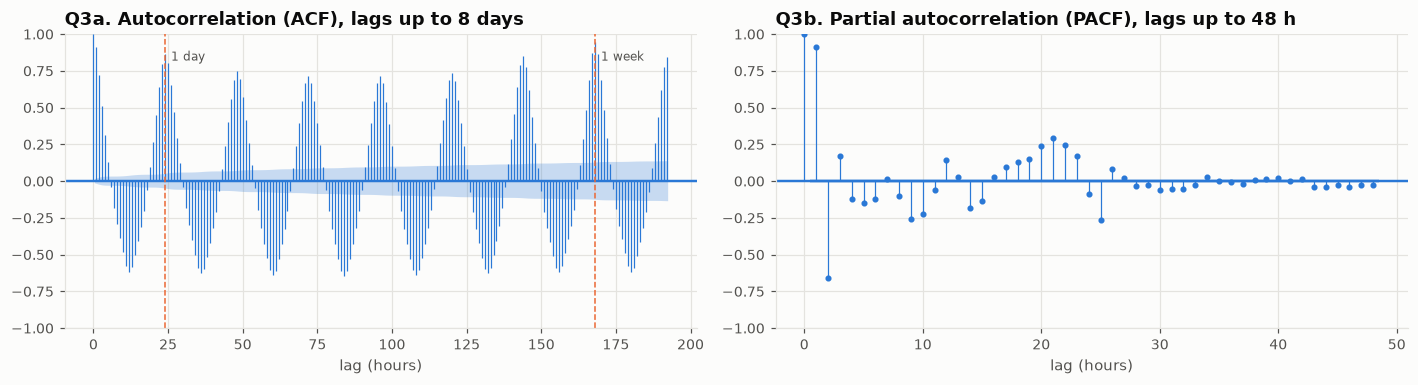

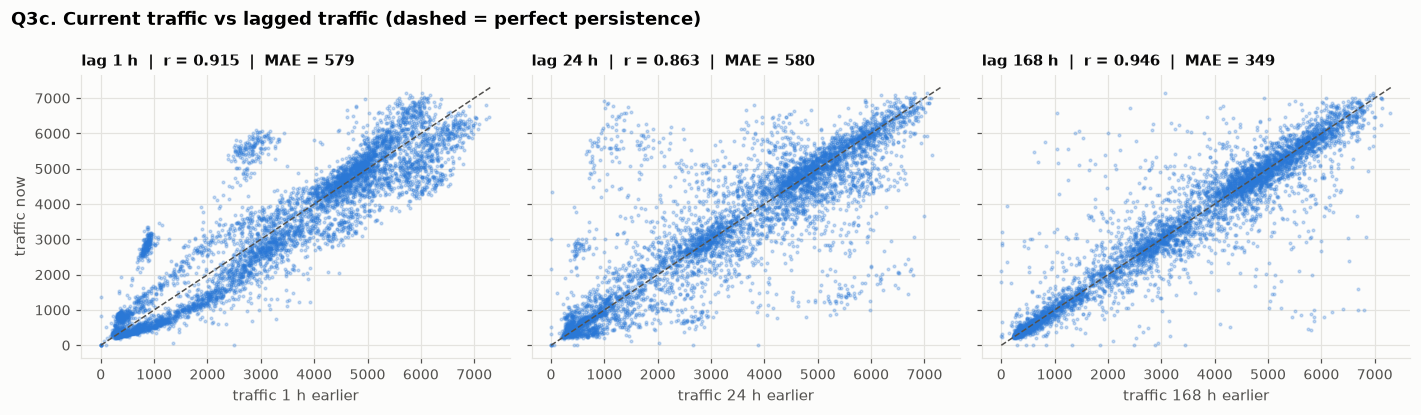

In [13]:
y = grid.traffic_volume
lags = [1, 2, 3, 6, 12, 24, 48, 72, 168, 336]
acf_vals = pd.Series({l: y.autocorr(l) for l in lags}, name="autocorrelation")
display(acf_vals.round(3).to_frame().T)

cont = grid.loc["2016-01-01":"2017-12-31", "traffic_volume"].interpolate(limit_direction="both")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
plot_acf(cont, lags=24*8, ax=axes[0], markersize=0, color=SERIES[0], vlines_kwargs={"colors": SERIES[0], "linewidth": 0.8})
axes[0].set_title("Q3a. Autocorrelation (ACF), lags up to 8 days"); axes[0].set_xlabel("lag (hours)")
for l in (24, 168):
    axes[0].axvline(l, color=SERIES[1], linestyle="--", linewidth=1)
axes[0].text(170, 0.82, "1 week", color=TEXT_SECONDARY, fontsize=8)
axes[0].text(26, 0.82, "1 day", color=TEXT_SECONDARY, fontsize=8)
plot_pacf(cont, lags=48, ax=axes[1], method="ywm", markersize=3, color=SERIES[0], vlines_kwargs={"colors": SERIES[0], "linewidth": 0.8})
axes[1].set_title("Q3b. Partial autocorrelation (PACF), lags up to 48 h"); axes[1].set_xlabel("lag (hours)")
fig.tight_layout(); save(fig, "q3_acf_pacf"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
sample = features.sample(6000, random_state=0)
for ax, lag in zip(axes, [1, 24, 168]):
    ax.scatter(sample[f"lag_{lag}"], sample.traffic_volume, s=3, alpha=0.25, color=SERIES[0])
    ax.plot([0, 7300], [0, 7300], color=TEXT_SECONDARY, linewidth=1, linestyle="--")
    mae = (features.traffic_volume - features[f"lag_{lag}"]).abs().mean()
    ax.set_title(f"lag {lag} h  |  r = {y.autocorr(lag):.3f}  |  MAE = {mae:,.0f}", fontsize=10)
    ax.set_xlabel(f"traffic {lag} h earlier")
axes[0].set_ylabel("traffic now")
fig.suptitle("Q3c. Current traffic vs lagged traffic (dashed = perfect persistence)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(); save(fig, "q3_lag_scatter"); plt.show()

**Interpretation.** Lag effects are strong and match the seasonal structure.
* **Lag 1 h: r = 0.915.** Very strong short-term momentum. It decays quickly (lag 3 h: 0.52) and turns **negative at lag 12 h (−0.62)**: 12 hours from a peak is a trough.
* **Lag 24 h: r = 0.863** (yesterday, same hour).
* **Lag 168 h: r = 0.946**, the **highest of all lags**. The same hour last week is a better predictor than the previous hour, because it matches both hour of day and day of week. Lag 336 h (two weeks) is still 0.941.
* The **PACF** has a large positive spike at lag 1 (≈ +0.91), a large negative spike at lag 2 (≈ −0.66), and a second cluster around 20–25 h. So the last 1–3 hours and the same time yesterday each add information beyond what the other lags explain.
* The scatter plots show this. As a naive forecast, *“same as last week”* has **MAE ≈ 349 veh/h**. *“Same as an hour ago”* has MAE ≈ 579, because it misses the steep rush-hour ramps.

**Decision:** include **lags 1, 2, 3, 24 and 168** as features. The lag-168 forecast is the **seasonal-naive baseline** the trained models must beat (Task 1C).

### Q4. Do external weather variables correlate with traffic over time?

,raw corr with traffic,corr with residual
temp_c,0.134,0.176
rain_1h,-0.014,-0.035
snow_1h,0.002,-0.018
clouds_all,0.081,-0.085


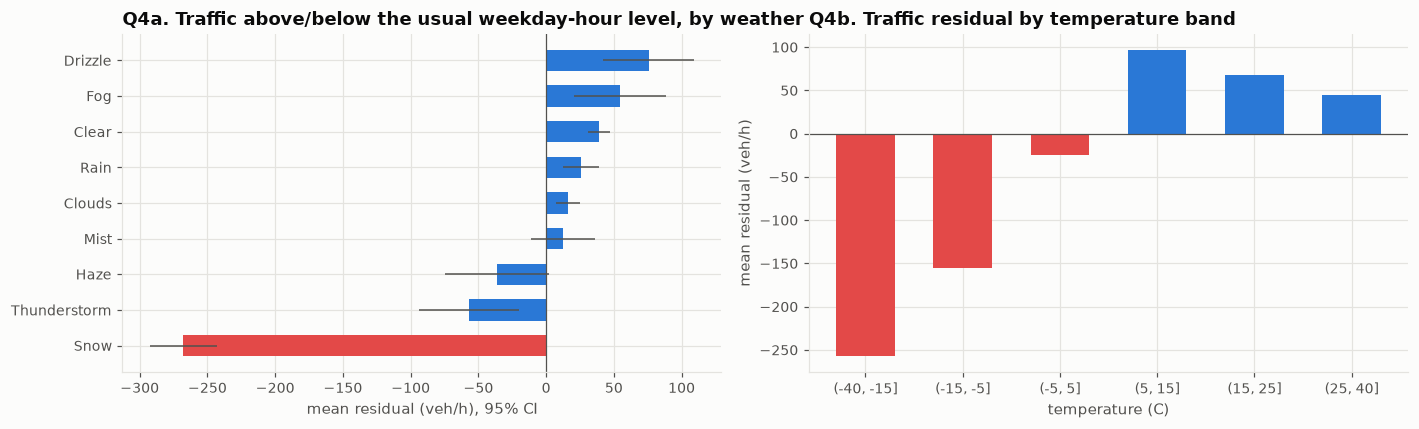

Weekday rush-hour mean: Clear 5925 vs Snow 5210  (-12.1%)
Monthly mean traffic vs monthly mean temperature: r = 0.46


In [14]:
f = features.copy()
f["expected"] = f.groupby(["day_of_week", "hour"]).traffic_volume.transform("mean")
f["residual"] = f.traffic_volume - f["expected"]          # traffic left after removing the weekly profile

cols = ["temp_c", "rain_1h", "snow_1h", "clouds_all"]
corr = pd.DataFrame({"raw corr with traffic": f[cols].corrwith(f.traffic_volume),
                     "corr with residual": f[cols].corrwith(f.residual)}).round(3)
display(corr)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = f.groupby("weather_main").residual.mean().sort_values().index
order = [o for o in order if (f.weather_main == o).sum() >= 100]
eff = f.groupby("weather_main").residual.agg(["mean", "sem", "size"]).loc[order]
colors = [SERIES[7] if v < -100 else SERIES[0] for v in eff["mean"]]
axes[0].barh(eff.index, eff["mean"], xerr=1.96 * eff["sem"], color=colors, height=0.6,
             error_kw={"ecolor": TEXT_SECONDARY, "linewidth": 1})
axes[0].axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
axes[0].set_title("Q4a. Traffic above/below the usual weekday-hour level, by weather")
axes[0].set_xlabel("mean residual (veh/h), 95% CI")

f["temp_bin"] = pd.cut(f.temp_c, [-40, -15, -5, 5, 15, 25, 40])
tb = f.groupby("temp_bin", observed=True).residual.mean()
axes[1].bar(tb.index.astype(str), tb.values, color=[SERIES[7] if v < 0 else SERIES[0] for v in tb.values], width=0.6)
axes[1].axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
axes[1].set_title("Q4b. Traffic residual by temperature band"); axes[1].set_xlabel("temperature (C)"); axes[1].set_ylabel("mean residual (veh/h)")
fig.tight_layout(); save(fig, "q4_weather_effect"); plt.show()

rush = f[(f.hour.isin([7, 8, 16, 17])) & (f.is_weekend == 0)]
r = rush.groupby("weather_main").traffic_volume.mean()
print(f"Weekday rush-hour mean: Clear {r['Clear']:.0f} vs Snow {r['Snow']:.0f}  ({r['Snow']/r['Clear']-1:+.1%})")

monthly = f.resample("ME")[["traffic_volume", "temp_c"]].mean().dropna()
print(f"Monthly mean traffic vs monthly mean temperature: r = {monthly.traffic_volume.corr(monthly.temp_c):.2f}")

**Interpretation.** The raw correlations look tiny (temperature r = 0.13, rain −0.01, snow ≈ 0). That is because hour of day dominates the variance and **masks** weather effects. After removing the usual weekday-hour level (the residual), the signal is clearer:
* **Snow is the only condition with a large effect:** about **−270 veh/h** below the normal level for that hour. In the **weekday rush hour**, snowy hours carry **~12% fewer vehicles** (5,210 vs 5,925 when clear). Thunderstorms show a small dip (≈ −57). Rain, drizzle, mist and fog have no meaningful effect (|effect| < 80 veh/h, which is within noise).
* **Temperature** has the strongest continuous link (residual r = 0.18). Very cold hours (< −15 °C) run **~260 veh/h below normal**, and mild hours (5–15 °C) about +100. Cold and snow occur together, so part of this is the winter dip from Q1. At the monthly level, mean traffic and mean temperature correlate at r = 0.46.
* Measured `rain_1h` and `snow_1h` amounts are weak predictors. They are zero in 95%+ of hours, and `snow_1h` is almost never recorded. The categorical `weather_main` is more informative.

**Conclusion:** weather is a **secondary driver**. It matters in winter and in snow, but explains far less than the calendar and lags. Weather features are kept in the model mainly to catch snow days.

### Q5. How do holidays change traffic compared with normal days?

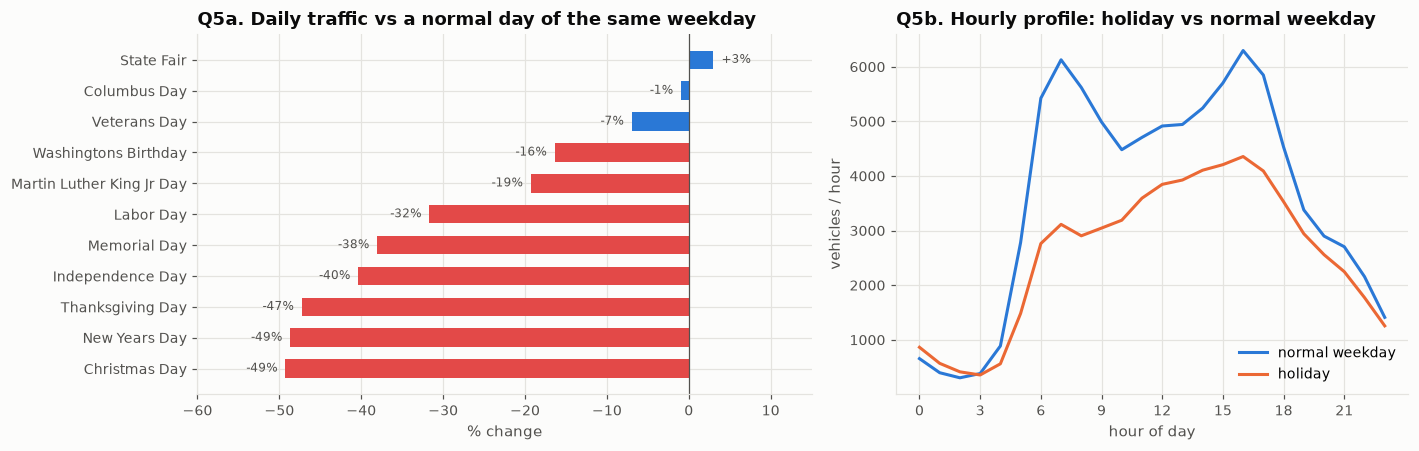

Average holiday effect: -27.2% over 53 complete holiday days


In [15]:
day_tot = grid.resample("D").agg({"traffic_volume": "sum", "is_holiday": "max"})
complete = grid.traffic_volume.resample("D").count() == 24      # only full days are comparable
day_tot = day_tot[complete]
day_tot["dow"] = day_tot.index.dayofweek
day_tot["holiday"] = grid.holiday.resample("D").first().reindex(day_tot.index)
normal = day_tot[day_tot.is_holiday == 0].groupby("dow").traffic_volume.mean()
hol = day_tot[day_tot.is_holiday == 1].copy()
hol["expected"] = hol.dow.map(normal)
hol["pct_diff"] = (hol.traffic_volume / hol.expected - 1) * 100
summary = hol.groupby("holiday").pct_diff.agg(["mean", "size"]).sort_values("mean")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
axes[0].barh(summary.index, summary["mean"], color=[SERIES[7] if v < -10 else SERIES[0] for v in summary["mean"]], height=0.6)
for i, v in enumerate(summary["mean"]):
    axes[0].text(v - 1 if v < 0 else v + 1, i, f"{v:+.0f}%", va="center", ha="right" if v < 0 else "left", fontsize=8, color=TEXT_SECONDARY)
axes[0].axvline(0, color=TEXT_SECONDARY, linewidth=0.8)
axes[0].set_title("Q5a. Daily traffic vs a normal day of the same weekday"); axes[0].set_xlabel("% change")
axes[0].set_xlim(-60, 15)

hp = grid[grid.is_holiday == 1].groupby(grid[grid.is_holiday == 1].index.hour).traffic_volume.mean()
wd = grid[(grid.is_holiday == 0) & (grid.index.dayofweek < 5)].groupby(lambda i: i.hour).traffic_volume.mean()
axes[1].plot(wd.index, wd, color=SERIES[0], linewidth=2, label="normal weekday")
axes[1].plot(hp.index, hp, color=SERIES[1], linewidth=2, label="holiday")
axes[1].set_title("Q5b. Hourly profile: holiday vs normal weekday"); axes[1].set_xlabel("hour of day"); axes[1].set_ylabel("vehicles / hour")
axes[1].set_xticks(range(0, 24, 3)); axes[1].legend()
fig.tight_layout(); save(fig, "q5_holidays"); plt.show()

print(f"Average holiday effect: {hol.pct_diff.mean():+.1f}% over {len(hol)} complete holiday days")

**Interpretation.** Holidays cut traffic by **27% on average** compared with a normal day of the same weekday. The effect differs a lot by holiday:
* **Christmas, New Year's Day and Thanksgiving: about −47% to −49%.** Close to half the traffic.
* **Independence Day (−40%), Memorial Day (−38%), Labor Day (−32%).** Strong reductions, typical of long-weekend Mondays.
* **MLK Day, Presidents' Day (−16% to −19%) and Veterans Day (−7%).** Partial: many employers stay open.
* **Columbus Day (≈0%) and the Minnesota State Fair (+3%).** No reduction. The State Fair is a regional event that *adds* trips.

The hourly view shows *why*: on holidays the **AM commuter peak disappears**, and the profile looks like a weekend. The binary `is_holiday` feature is kept. Because the effect varies by holiday, the model will still make its largest errors on rare holidays (only 5 examples of each in six years).

### Q6. Do recent moving averages tell us whether this hour will be above or below last week? *(lagged features + moving averages)*

Correlation between the two deviations: r = 0.472  (n = 39,398)


,mean (this hour - same hour last week)
quintile,
much lower,-402.0
lower,-60.0
similar,6.0
higher,79.0
much higher,386.0


Seasonal-naive MAE: 349.9 | MA-adjusted seasonal-naive MAE: 327.4  (-6.4%)


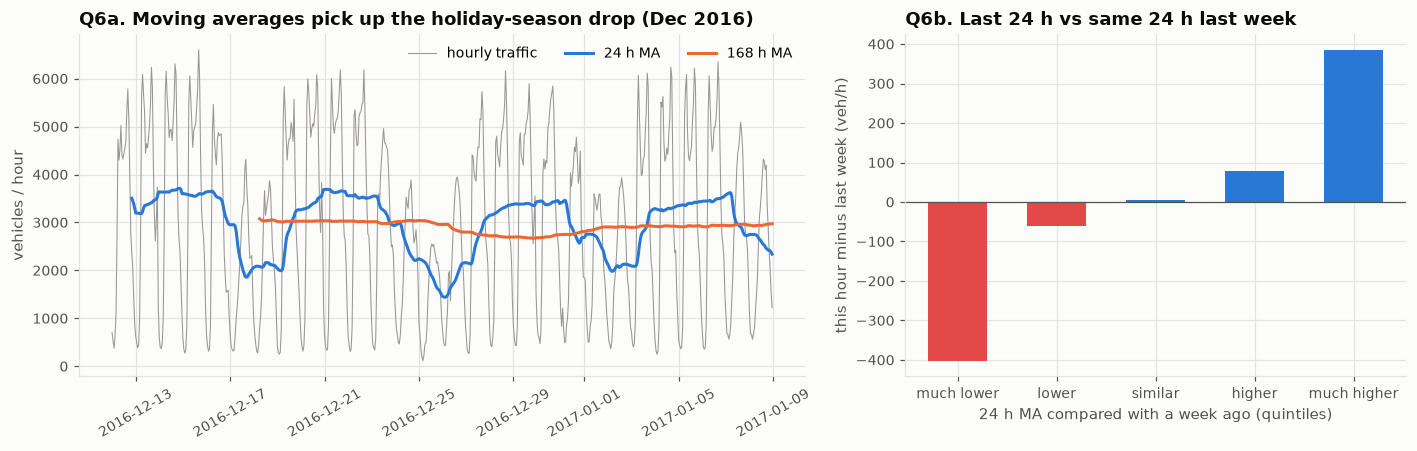

In [16]:
y = grid.traffic_volume
ma24 = y.shift(1).rolling(24, min_periods=24).mean()          # last 24 h known before hour t
dev_now = y - y.shift(168)                                     # this hour vs same hour last week
dev_ma = ma24 - ma24.shift(168)                                # last 24 h vs the same 24 h last week
q6 = pd.concat({"dev_now": dev_now, "dev_ma": dev_ma}, axis=1).dropna()
print(f"Correlation between the two deviations: r = {q6.dev_now.corr(q6.dev_ma):.3f}  (n = {len(q6):,})")

q6["quintile"] = pd.qcut(q6.dev_ma, 5, labels=["much lower", "lower", "similar", "higher", "much higher"])
by_q = q6.groupby("quintile", observed=True).dev_now.mean()
display(by_q.round(0).to_frame("mean (this hour - same hour last week)"))

naive = y.shift(168)
adjusted = y.shift(168) * (ma24 / ma24.shift(168))             # last week's value scaled by the recent level change
mae_naive = (y - naive).abs().mean(); mae_adj = (y - adjusted).abs().mean()
print(f"Seasonal-naive MAE: {mae_naive:.1f} | MA-adjusted seasonal-naive MAE: {mae_adj:.1f}  ({mae_adj/mae_naive-1:+.1%})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.45, 1]})
win = grid.loc["2016-12-12":"2017-01-08", "traffic_volume"]
axes[0].plot(win.index, win, color=NEUTRAL, linewidth=0.7, label="hourly traffic")
axes[0].plot(win.index, win.shift(1).rolling(24, min_periods=20).mean(), color=SERIES[0], linewidth=2, label="24 h MA")
axes[0].plot(win.index, win.shift(1).rolling(168, min_periods=150).mean(), color=SERIES[1], linewidth=2, label="168 h MA")
axes[0].set_title("Q6a. Moving averages pick up the holiday-season drop (Dec 2016)")
axes[0].set_ylabel("vehicles / hour"); axes[0].legend(ncol=3, loc="upper right")
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(by_q.index.astype(str), by_q.values, color=[SERIES[7] if v < 0 else SERIES[0] for v in by_q.values], width=0.6)
axes[1].axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
axes[1].set_title("Q6b. Last 24 h vs same 24 h last week"); axes[1].set_xlabel("24 h MA compared with a week ago (quintiles)")
axes[1].set_ylabel("this hour minus last week (veh/h)")
fig.tight_layout(); save(fig, "q6_moving_average_deviation"); plt.show()

**Interpretation.** On their own, longer moving averages correlate poorly with the *hourly* target (24 h MA r ≈ 0.19). They smooth away the daily cycle, which is the point: they measure the **current level** of traffic, not the hour-of-day shape.

Combined with the weekly lag they are useful. When the last 24 hours ran **below the same 24 hours last week** (bottom quintile), the current hour is on average **~400 veh/h below last week's value**. When the last 24 hours ran higher, the current hour is ~390 above. The correlation between the two deviations is **r = 0.47**. Scaling last week's value by the ratio of the two 24 h MAs lowers the seasonal-naive error from **MAE 350 to 327 (−6.4%)**, with no model at all.

Q6a shows this around Christmas 2016. The 24 h MA reacts within a day to the holiday-season drop; the 168 h MA moves slowly and gives the baseline. **Decision:** keep both the short-memory lags (1–3 h, 24 h, 168 h) and the **3 h, 24 h and 168 h moving averages** (plus a 24 h rolling standard deviation for volatility) as features. Together they let the model scale its weekly pattern to the current level.

---
## Summary of EDA → modelling decisions
| Finding | Consequence for the pipeline |
|---|---|
| Hourly data, 2012-10 → 2018-09, duplicates = extra weather rows | Collapse to one row per hour, keep most severe weather |
| 22.8% missing hours, mostly 1 h; one 10-month outage | Interpolate gaps ≤ 3 h, never fill long gaps, drop affected windows |
| 0 K temperatures, 9,831 mm rain | Set to NaN before imputation |
| Strong daily and weekly seasonality, no real trend | Calendar features (hour, weekday, weekend, cyclical encodings), no de-trending |
| Lag 168 h r = 0.946, lag 1 h r = 0.915 | Lags 1, 2, 3, 24, 168; seasonal-naive baseline |
| Moving averages capture level shifts | 3/24/168 h MAs + 24 h std |
| Snow and extreme cold reduce traffic; holidays −27% | Keep weather one-hots, temperature, `is_holiday` |